In [1]:
from diffusers import AutoencoderKL
from PIL import Image
import torch
import torchvision.transforms as T
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
from math import log10
from skimage.metrics import structural_similarity as ssim
from diffusers.models.autoencoders.vae import DiagonalGaussianDistribution
from medvae import MVAE

In [2]:
# Load the VAE (e.g., from Stable Diffusion)
vae = AutoencoderKL.from_pretrained("stabilityai/stable-diffusion-2", subfolder="vae")
vae.eval().cuda()  # Use CUDA if available

medvae_model = MVAE(model_name="medvae_4_3_2d", modality="mri")
medvae_model.eval().cuda()
medvae_model.requires_grad_(False)

making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 3, 64, 64) = 12288 dimensions.
making attention of type 'vanilla' with 512 in_channels
Restored from /home/sysgen/.cache/huggingface/hub/models--stanfordmimi--MedVAE/snapshots/8040c5ccb7a51eff6b4cef513c7f20bd1bda983d/model_weights/vae_4x_3c_2D.ckpt with 0 missing and 0 unexpected keys


MVAE(
  (model): AutoencoderKL(
    (encoder): Encoder(
      (conv_in): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (down): ModuleList(
        (0): Module(
          (block): ModuleList(
            (0-1): 2 x ResnetBlock(
              (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
              (conv1): LoraInjectedConv2d(
                (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
                (lora_down): Conv2d(128, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
                (dropout): Dropout(p=0.1, inplace=False)
                (lora_up): Conv2d(4, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
                (selector): Identity()
              )
              (norm2): GroupNorm(32, 128, eps=1e-06, affine=True)
              (dropout): Dropout(p=0.0, inplace=False)
              (conv2): LoraInjectedConv2d(
                (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1)

In [3]:
id = '00178'

image_path_t1n = f"/home/sysgen/Desktop/Priyank/Datasets/brats24/BraTS-GLI/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-{id}-000/BraTS-GLI-{id}-000-t1c.nii.gz"  # Replace with your NIfTI image path
image_path_t2w = f"/home/sysgen/Desktop/Priyank/Datasets/brats24/BraTS-GLI/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-{id}-000/BraTS-GLI-{id}-000-t1n.nii.gz"  # Replace with your NIfTI image path
image_path_flair = f"/home/sysgen/Desktop/Priyank/Datasets/brats24/BraTS-GLI/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-{id}-000/BraTS-GLI-{id}-000-t2f.nii.gz"  # Replace with your NIfTI image path
image_path_t1ce = f"/home/sysgen/Desktop/Priyank/Datasets/brats24/BraTS-GLI/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-{id}-000/BraTS-GLI-{id}-000-t2w.nii.gz"  # Replace with your NIfTI image path

image_list = [image_path_t1n, image_path_t2w, image_path_flair, image_path_t1ce]


In [4]:
# --- Step 1: Load NIfTI image (.nii.gz) ---

def load_nifti_image(image_path):
    image = nib.load(image_path)
    volume = image.get_fdata()  # shape: [H, W, D] or [X, Y, Z]
    
    print(f"Volume shape: {volume.shape}")
    
    slice_idx = volume.shape[2] // 2  # axial slice
    slice_2d = volume[:, :, slice_idx]
    
    # Normalize slice to [0, 255] and convert to uint8
    slice_norm = (slice_2d - np.min(slice_2d)) / (np.max(slice_2d) - np.min(slice_2d) + 1e-5)
    slice_uint8 = (slice_norm * 255).astype(np.uint8)
    
    return slice_uint8


In [5]:
def preprocess_image(image, target_size=(512, 512)):
    # Convert to PIL and then RGB (3 channels)
    image = Image.fromarray(image).convert("RGB")
    
    # --- Step 3: Preprocess image for VAE ---
    transform = T.Compose([
        T.Resize(target_size),
        T.ToTensor(),
        T.Normalize([0.5], [0.5]),  # Normalize to [-1, 1]
    ])
    input_tensor = transform(image).unsqueeze(0).cuda()  # [1, 3, H, W]
    
    return input_tensor

In [6]:
def encode_and_decode(input_tensor, original_size):
    # --- Step 4: Encode and Decode ---
    with torch.no_grad():
        print(f'input_tensor.shape = {input_tensor.shape}')
        
        latents = vae.encode(input_tensor).latent_dist
        #latents_sample = latents.sample() * 0.18215
        #decoded = vae.decode(latents_sample / 0.18215).sample
        latents_sample = latents.sample()
        decoded = vae.decode(latents_sample).sample
        
        print(f'decoded image min:{decoded.min()}, max:{decoded.max()}')

    # --- Step 5: Convert output back to image ---
    decoded = (decoded.clamp(-1, 1) + 1) / 2
    decoded_image = T.ToPILImage()(decoded.squeeze().cpu())
    
    # Resize decoded image back to original shape
    decoded_image_resized = decoded_image.resize(original_size[::-1], resample=Image.BICUBIC).convert("L")  # PIL uses (W, H)
    
    '''
    img_np = decoded_image_resized = np.asarray(decoded_image_resized)
    r, g, b = img_np[:,:,0], img_np[:,:,1], img_np[:,:,2]

    if np.array_equal(r, g) and np.array_equal(g, b):
        print("All channels are the same — image is grayscale in RGB format.")
    else:
        print("Channels differ — image is truly RGB.")
    '''
    
    decoded_image_resized = np.asarray(decoded_image_resized)
    
    return latents, latents_sample, decoded, decoded_image_resized
    


In [7]:
def calculate_psnr(original, generated, max_val=255.0):
    # Ensure both images are numpy arrays and of type float64
    original = np.array(original).astype(np.float64)
    generated = np.array(generated).astype(np.float64)

    mse = np.mean((original - generated) ** 2)
    if mse == 0:
        return float('inf')  # No error = infinite PSNR

    psnr = 10 * log10((max_val ** 2) / mse)
    return psnr

Volume shape: (240, 240, 155)
input_tensor.shape = torch.Size([1, 3, 512, 512])
decoded image min:-1.059544324874878, max:0.8981221914291382
Error in loading /home/sysgen/Desktop/Priyank/Datasets/brats24/BraTS-GLI/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00178-000/BraTS-GLI-00178-000-t1c.nii.gz with error: applying transform <medvae.utils.loaders.MonaiImageOpen object at 0x70921c870eb0>
MedVAE image shape = torch.Size([1, 1, 384, 384])
MedVAE Latents shape = torch.Size([3, 96, 96])
MedVAE decoded image shape = torch.Size([3, 384, 384])
Shape of Latents Mean/std: torch.Size([1, 4, 64, 64])
Min value of Mean/std: -20.300411224365234 and max value: 33.10365295410156
Shape of Latents Mean/std: torch.Size([1, 4, 64, 64])
Min value of Mean/std: 3.0590231858695915e-07 and max value: 0.002943619154393673


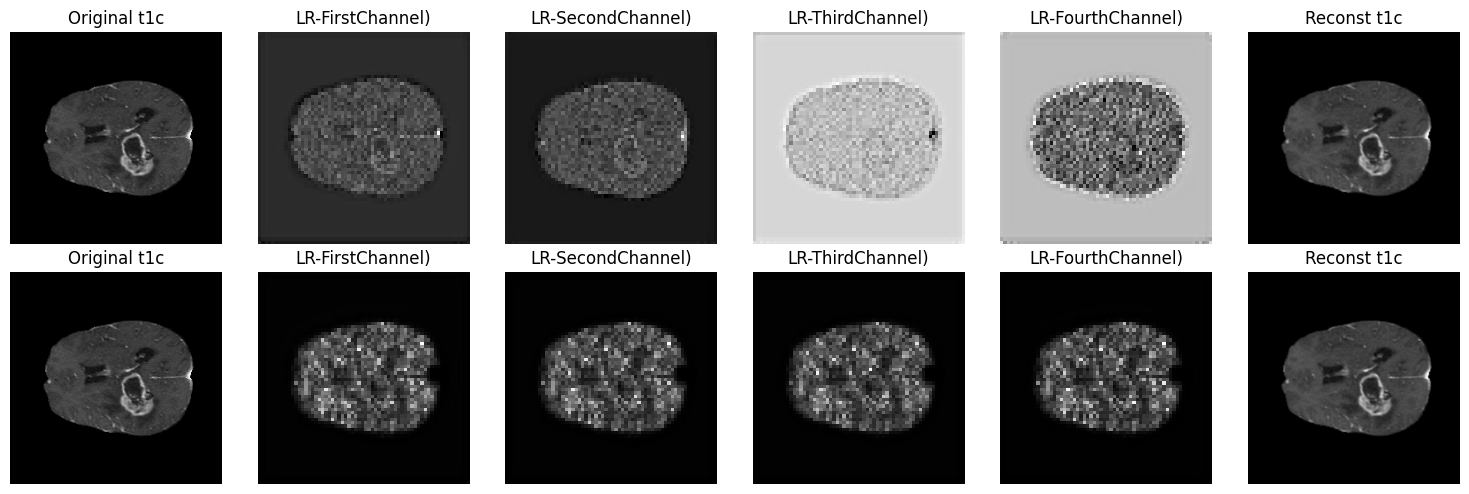

Shape of Image: (240, 240)
Shape of Decoded Image: (240, 240)
Image Type: t1c, PSNR: 38.64 dB
Image Type: t1c, SSIM: 0.9695

MedVAE Image Type: t1c, PSNR: 4.38 dB
MedVAE Image Type: t1c, SSIM: 0.0175

Volume shape: (240, 240, 155)
input_tensor.shape = torch.Size([1, 3, 512, 512])
decoded image min:-1.033584713935852, max:0.9038040041923523
Error in loading /home/sysgen/Desktop/Priyank/Datasets/brats24/BraTS-GLI/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00178-000/BraTS-GLI-00178-000-t1n.nii.gz with error: applying transform <medvae.utils.loaders.MonaiImageOpen object at 0x70921d644130>
MedVAE image shape = torch.Size([1, 1, 384, 384])
MedVAE Latents shape = torch.Size([3, 96, 96])
MedVAE decoded image shape = torch.Size([3, 384, 384])
Shape of Latents Mean/std: torch.Size([1, 4, 64, 64])
Min value of Mean/std: -21.16904067993164 and max value: 18.518085479736328
Shape of Latents Mean/std: torch.Size([1, 4, 64, 64])
Min value of Mean/std: 3.0590231858695915e-07 and max v

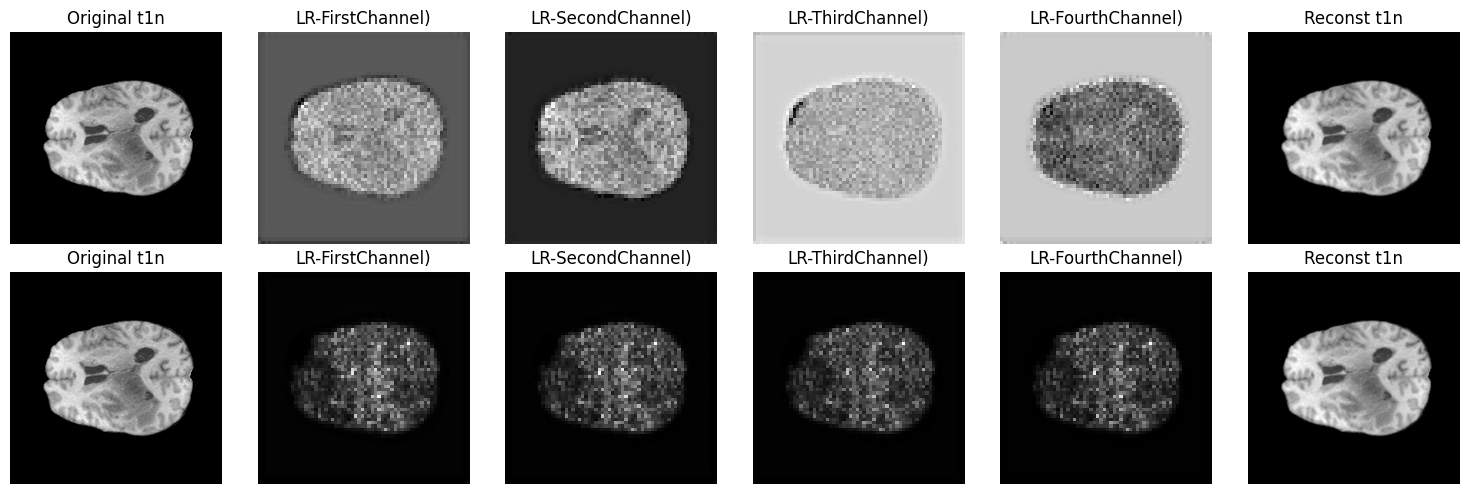

Shape of Image: (240, 240)
Shape of Decoded Image: (240, 240)
Image Type: t1n, PSNR: 36.95 dB
Image Type: t1n, SSIM: 0.9756

MedVAE Image Type: t1n, PSNR: 4.38 dB
MedVAE Image Type: t1n, SSIM: 0.0175

Volume shape: (240, 240, 155)
input_tensor.shape = torch.Size([1, 3, 512, 512])
decoded image min:-1.03933846950531, max:0.7740063667297363
Error in loading /home/sysgen/Desktop/Priyank/Datasets/brats24/BraTS-GLI/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00178-000/BraTS-GLI-00178-000-t2f.nii.gz with error: applying transform <medvae.utils.loaders.MonaiImageOpen object at 0x70921ca624d0>
MedVAE image shape = torch.Size([1, 1, 384, 384])
MedVAE Latents shape = torch.Size([3, 96, 96])
MedVAE decoded image shape = torch.Size([3, 384, 384])
Shape of Latents Mean/std: torch.Size([1, 4, 64, 64])
Min value of Mean/std: -30.346820831298828 and max value: 27.320932388305664
Shape of Latents Mean/std: torch.Size([1, 4, 64, 64])
Min value of Mean/std: 3.0590231858695915e-07 and max v

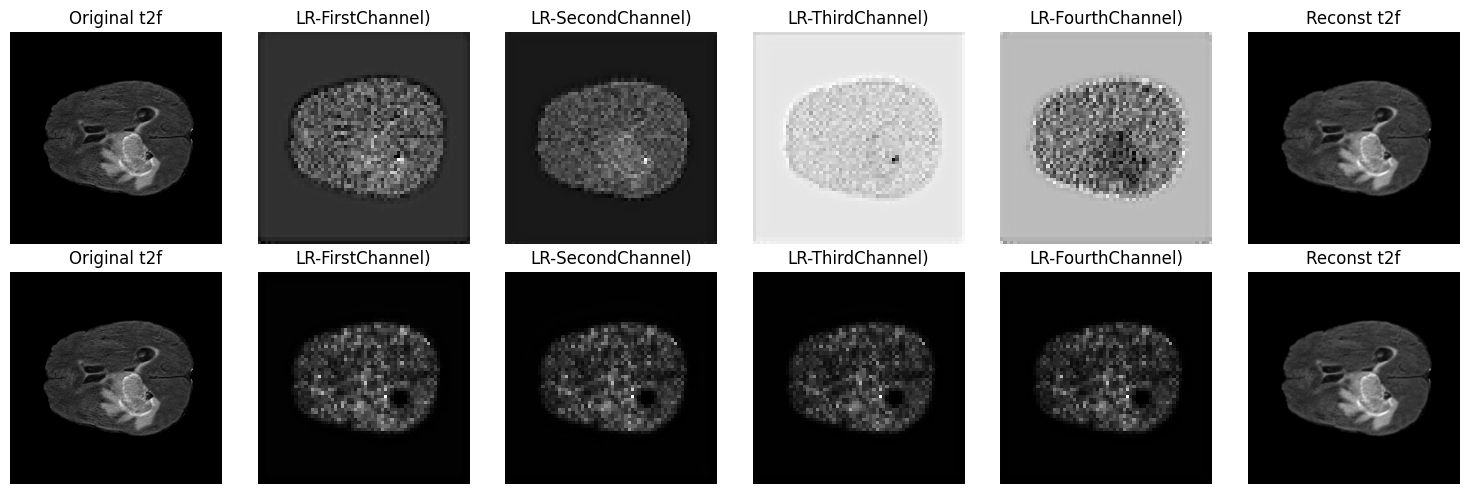

Shape of Image: (240, 240)
Shape of Decoded Image: (240, 240)
Image Type: t2f, PSNR: 36.73 dB
Image Type: t2f, SSIM: 0.9513

MedVAE Image Type: t2f, PSNR: 4.38 dB
MedVAE Image Type: t2f, SSIM: 0.0175

Volume shape: (240, 240, 155)
input_tensor.shape = torch.Size([1, 3, 512, 512])
decoded image min:-1.0328011512756348, max:0.955535352230072
Error in loading /home/sysgen/Desktop/Priyank/Datasets/brats24/BraTS-GLI/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00178-000/BraTS-GLI-00178-000-t2w.nii.gz with error: applying transform <medvae.utils.loaders.MonaiImageOpen object at 0x70921c20a080>
MedVAE image shape = torch.Size([1, 1, 384, 384])
MedVAE Latents shape = torch.Size([3, 96, 96])
MedVAE decoded image shape = torch.Size([3, 384, 384])
Shape of Latents Mean/std: torch.Size([1, 4, 64, 64])
Min value of Mean/std: -20.253948211669922 and max value: 26.61674690246582
Shape of Latents Mean/std: torch.Size([1, 4, 64, 64])
Min value of Mean/std: 3.0590231858695915e-07 and max v

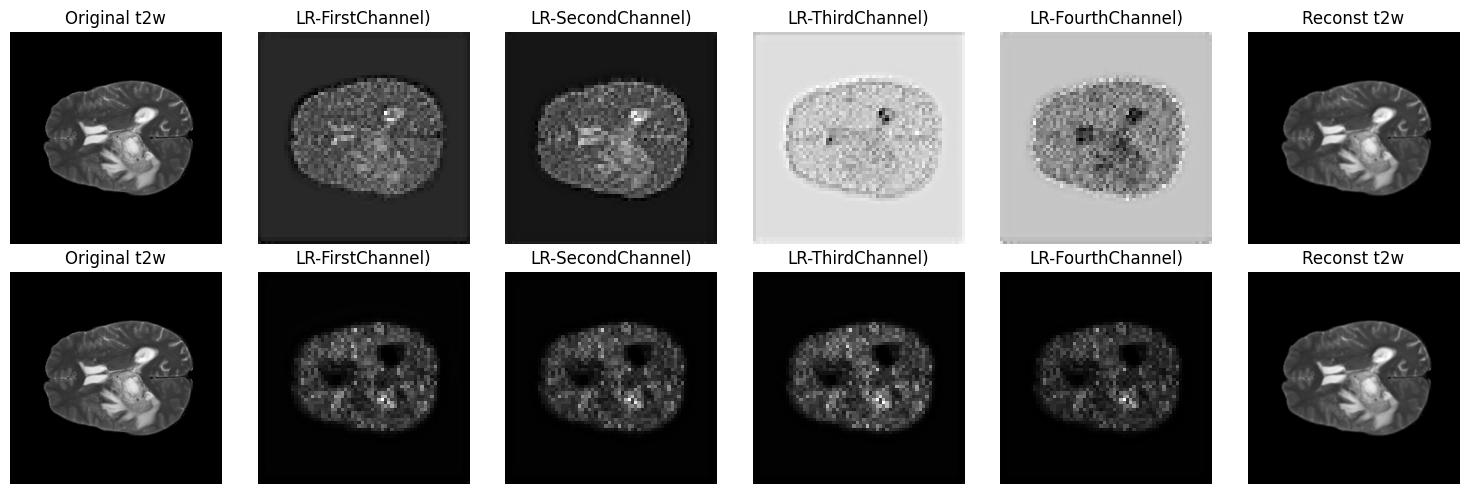

Shape of Image: (240, 240)
Shape of Decoded Image: (240, 240)
Image Type: t2w, PSNR: 39.80 dB
Image Type: t2w, SSIM: 0.9871

MedVAE Image Type: t2w, PSNR: 4.38 dB
MedVAE Image Type: t2w, SSIM: 0.0175



In [ ]:
for image_path in image_list:
    image_type = image_path.split('-')[-1].split('.')[0]  # Extract the image type from the filename
    slice_uint8 = load_nifti_image(image_path)
    original_size = slice_uint8.shape  # Get original size for later use
    input_tensor = preprocess_image(slice_uint8)
    
    # Encode and decode the image
    latents, latents_sample, decoded, decoded_image_resized = encode_and_decode(input_tensor, original_size)
    
    
    
    
    medvae_img = medvae_model.apply_transform(image_path).to('cuda')
    print(f'MedVAE image shape = {medvae_img.shape}')
    medvae_img = medvae_img.repeat(1, 3, 1, 1)  # shape: [1, 3, 384, 384]
    
    with torch.no_grad():
        dec_medvae, latents_medvae = medvae_model(medvae_img, decode=True)
    
    print(f'MedVAE Latents shape = {latents_medvae.shape}')
    
    print(f'MedVAE decoded image shape = {dec_medvae.shape}')
    
    
    fig, ax = plt.subplots(2, 6, figsize=(15, 5))
    for i in range(2):
        if i == 0:
            x = latents.mean
        else:
            x = latents.std
        
        
        print(f'Shape of Latents Mean/std: {x.shape}')
        print(f'Min value of Mean/std: {x.min()} and max value: {x.max()}')
        
        ax[i, 0].imshow(slice_uint8, cmap='gray')
        ax[i, 0].set_title(f"Original {image_type}")
        ax[i, 0].axis('off')
        ax[i, 1].imshow(x.squeeze().cpu().numpy()[0], cmap='gray')
        ax[i, 1].set_title("LR-FirstChannel)")
        ax[i, 1].axis('off')
        ax[i, 2].imshow(x.squeeze().cpu().numpy()[1], cmap='gray')
        ax[i, 2].set_title("LR-SecondChannel)")
        ax[i, 2].axis('off')
        ax[i, 3].imshow(x.squeeze().cpu().numpy()[2], cmap='gray')
        ax[i, 3].set_title("LR-ThirdChannel)")
        ax[i, 3].axis('off')
        ax[i, 4].imshow(x.squeeze().cpu().numpy()[3], cmap='gray')
        ax[i, 4].set_title("LR-FourthChannel)")
        ax[i, 4].axis('off')
        ax[i, 5].imshow(decoded_image_resized, cmap='gray')
        ax[i, 5].set_title(f"Reconst {image_type}")
        ax[i, 5].axis('off')
    plt.tight_layout()
    plt.show()
    
    print('Shape of Image:', slice_uint8.shape)
    print('Shape of Decoded Image:', decoded_image_resized.shape)
    
    psnr = calculate_psnr(original=slice_uint8, generated=decoded_image_resized, max_val=255.0)
    print(f'Image Type: {image_type}, PSNR: {psnr:.2f} dB')
    
    ssim_score = ssim(slice_uint8, decoded_image_resized, data_range=decoded_image_resized.max() - decoded_image_resized.min())
    print(f'Image Type: {image_type}, SSIM: {ssim_score:.4f}\n')
    
    
    
    medvae_img = medvae_img.detach().cpu().numpy().squeeze()
    dec_medvae = dec_medvae.detach().cpu().numpy().squeeze()
    latents_medvae = latents_medvae.detach().cpu().numpy().squeeze()
    
    fig, ax = plt.subplots(1, 3, figsize=(7, 7))
    ax[0, 0].imshow(medvae_img, cmap='gray')
    ax[0, 0].set_title(f"Original {image_type}")
    ax[0, 0].axis('off')
    
    ax[0, 1].imshow(latents_medvae, cmap='gray')
    ax[0, 1].set_title(f"Latent {image_type}")
    ax[0, 1].axis('off')
    
    ax[0, 0].imshow(dec_medvae, cmap='gray')
    ax[0, 1].set_title(f"Reconst {image_type}")
    ax[0, 2].axis('off')
    plt.tight_layout()
    plt.show()
    
    psnr = calculate_psnr(original=medvae_img, generated=dec_medvae, max_val=dec_medvae.max())
    print(f'MedVAE Image Type: {image_type}, PSNR: {psnr:.2f} dB')
    
    ssim_score = ssim(medvae_img, dec_medvae, data_range=dec_medvae.max() - dec_medvae.min(), channel_axis=0)
    print(f'MedVAE Image Type: {image_type}, SSIM: {ssim_score:.4f}\n')
    
    
    
    

In [9]:
def plot(original, means, stds, reconst):
    fig, ax = plt.subplots(2, 6, figsize=(15, 5))
    for i in range(2):
        if i == 0:
            x = means
        else:
            x = stds
        
        print(f'Shape of Latents Mean/std: {x.shape}')
        
        ax[i, 0].imshow(original, cmap='gray')
        ax[i, 0].set_title("Original")
        ax[i, 0].axis('off')
        ax[i, 1].imshow(x.squeeze().cpu().numpy()[0], cmap='gray')
        ax[i, 1].set_title("LR-FirstChannel)")
        ax[i, 1].axis('off')
        ax[i, 2].imshow(x.squeeze().cpu().numpy()[1], cmap='gray')
        ax[i, 2].set_title("LR-SecondChannel)")
        ax[i, 2].axis('off')
        ax[i, 3].imshow(x.squeeze().cpu().numpy()[2], cmap='gray')
        ax[i, 3].set_title("LR-ThirdChannel)")
        ax[i, 3].axis('off')
        ax[i, 4].imshow(x.squeeze().cpu().numpy()[3], cmap='gray')
        ax[i, 4].set_title("LR-FourthChannel)")
        ax[i, 4].axis('off')
        ax[i, 5].imshow(reconst, cmap='gray')
        ax[i, 5].set_title("Reconst")
        ax[i, 5].axis('off')
    plt.tight_layout()
    plt.show()

original_size = (240, 240)
input_tensor.shape = torch.Size([1, 3, 256, 256])
decoded image min:-1.052825927734375, max:0.9959161281585693
input_tensor.shape = torch.Size([1, 3, 256, 256])
decoded image min:-1.0327167510986328, max:1.0479549169540405
input_tensor.shape = torch.Size([1, 3, 256, 256])
decoded image min:-1.0665801763534546, max:0.932776689529419
Shape of Latents Mean/std: torch.Size([1, 4, 32, 32])
Shape of Latents Mean/std: torch.Size([1, 4, 32, 32])


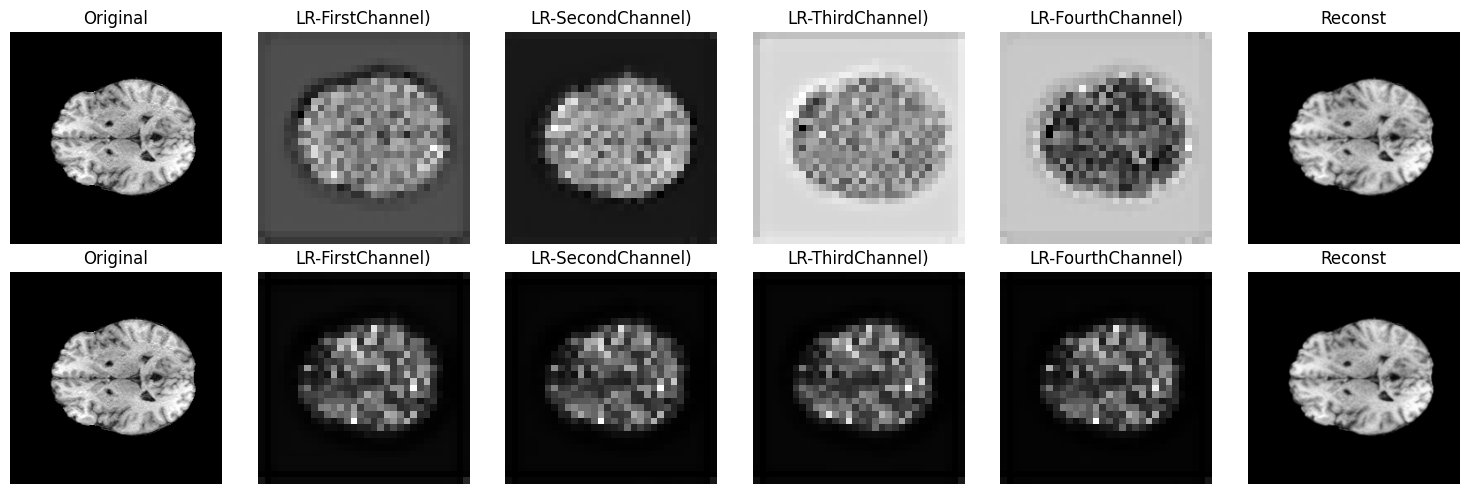

Shape of Latents Mean/std: torch.Size([1, 4, 32, 32])
Shape of Latents Mean/std: torch.Size([1, 4, 32, 32])


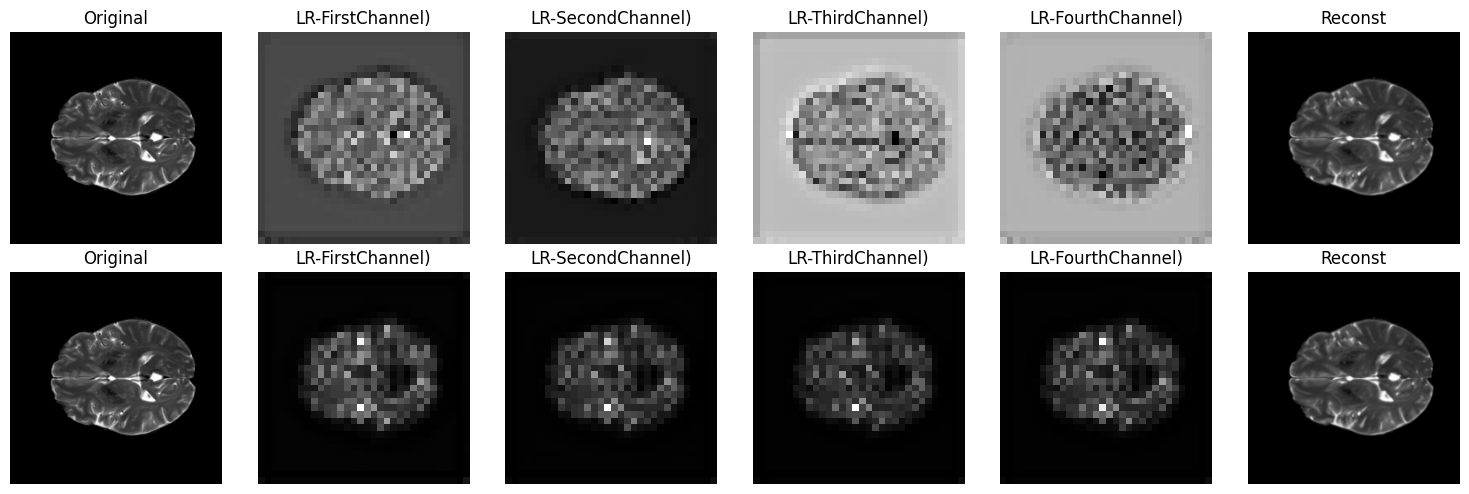

Shape of Latents Mean/std: torch.Size([1, 4, 32, 32])
Shape of Latents Mean/std: torch.Size([1, 4, 32, 32])


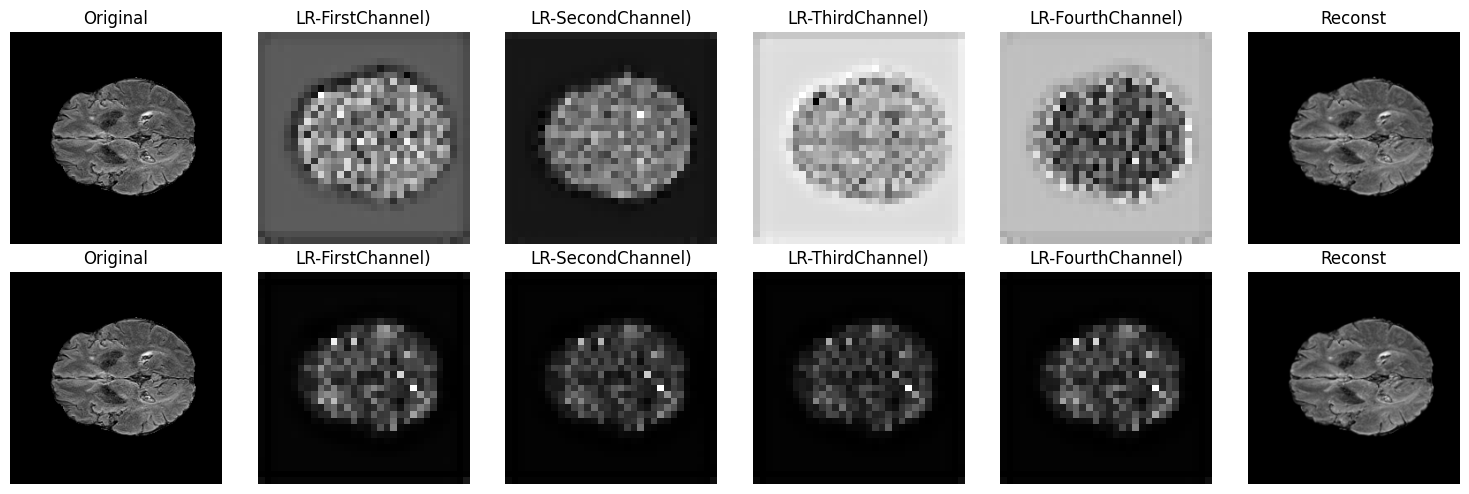

In [10]:
val_file = '/home/sysgen/Desktop/Priyank/Datasets/brats24/BraTS-GLI/numpy_files_val/BraTS-GLI-01066-000/070.npz'
val_file_data = np.load(val_file)

val_t1 = val_file_data['t1'].squeeze()
val_t1ce = val_file_data['t1ce'].squeeze()
val_t2 = val_file_data['t2'].squeeze()
val_flair = val_file_data['flair'].squeeze()

original_size = val_t1.shape  # Get original size for later use

print(f'original_size = {original_size}')

# Goal to generate flair from t1 and t2
t1_input_tensor = preprocess_image(val_t1, target_size=(256, 256))
t2_input_tensor = preprocess_image(val_t2, target_size=(256, 256))
flair_input_tensor = preprocess_image(val_flair, target_size=(256, 256))

latents_t1, latents_sample, decoded, decoded_image_resized = encode_and_decode(t1_input_tensor, original_size)
latents_t2, latents_sample_t2, decoded_t2, decoded_image_resized_t2 = encode_and_decode(t2_input_tensor, original_size)
latents_flair, latents_sample_flair, decoded_flair, decoded_image_resized_flair = encode_and_decode(flair_input_tensor, original_size)

plot(val_t1, latents_t1.mean, latents_t1.std, decoded_image_resized)
plot(val_t2, latents_t2.mean, latents_t2.std, decoded_image_resized_t2)
plot(val_flair, latents_flair.mean, latents_flair.std, decoded_image_resized_flair)



torch.Size([1, 4, 32, 32]) torch.Size([1, 4, 32, 32]) torch.Size([1, 4, 32, 32]) torch.Size([1, 4, 32, 32]) torch.Size([1, 4, 32, 32]) torch.Size([1, 4, 32, 32]) torch.Size([1, 4, 32, 32]) torch.Size([1, 4, 32, 32])
torch.Size([1, 16, 32, 32]) torch.Size([1, 16, 32, 32])
torch.Size([1, 4, 32, 32]) torch.Size([1, 4, 32, 32])
torch.Size([1, 3, 256, 256])
57600
Shape of Latents Mean/std: torch.Size([1, 4, 32, 32])
Shape of Latents Mean/std: torch.Size([1, 4, 32, 32])


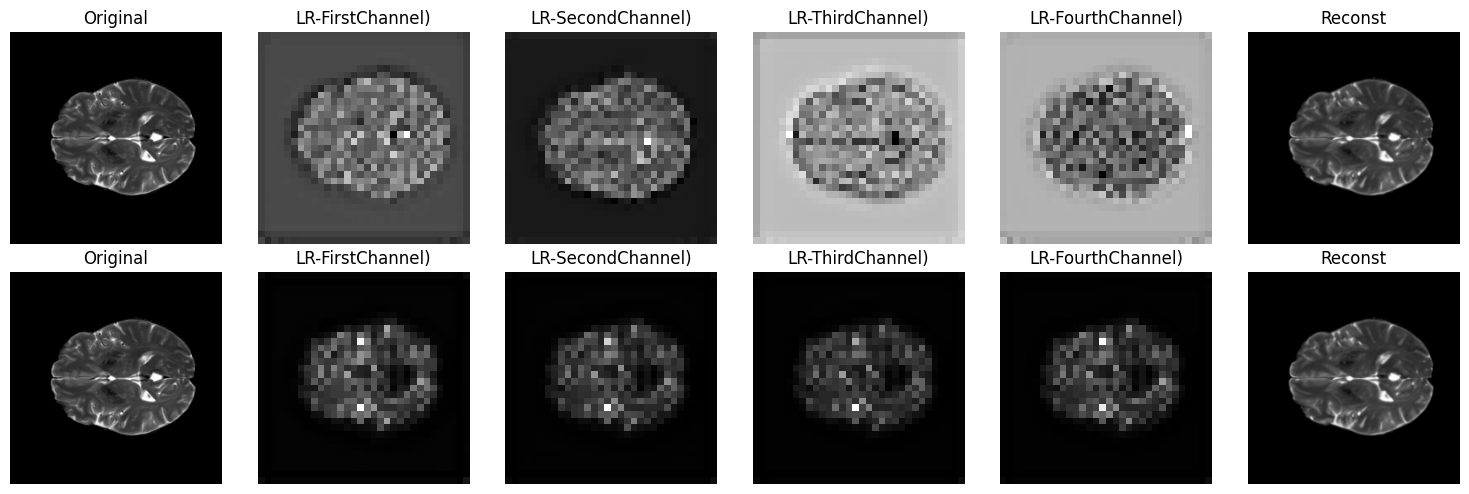

Shape of Latents Mean/std: torch.Size([1, 4, 32, 32])
Shape of Latents Mean/std: torch.Size([1, 4, 32, 32])


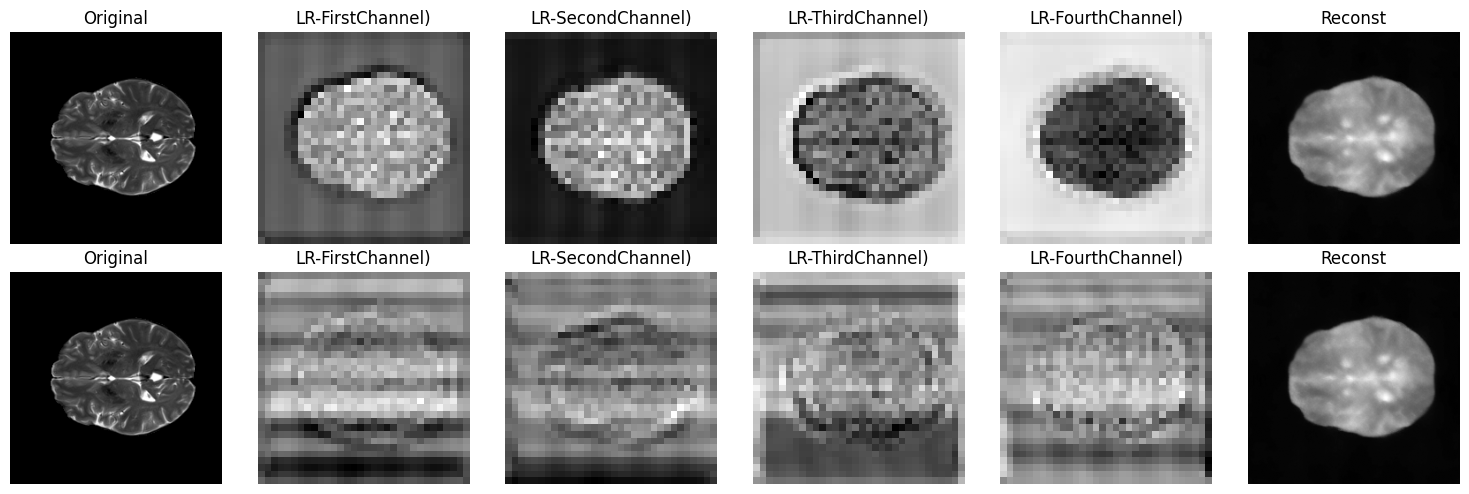

0
246
1
151
Image Type: t2w, PSNR: 22.67 dB
Image Type: t2w, SSIM: 0.2976

Loss Value: 4.277760982513428


In [11]:
from model import LatentFusionModel, LatentFusionTransformerModel, LatentFusionTransformerModel_Cross

#model = LatentFusionModel()
#model = LatentFusionTransformerModel(depth=5, embedding_dim=32, num_heads=4)
model = LatentFusionTransformerModel_Cross(depth=3, embedding_dim=32, num_heads=4)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

model.load_state_dict(torch.load('/home/sysgen/Desktop/Priyank/MRI_Gen/checkpoints/best.pth', map_location=device)['model'])
model.eval()


#one_hot_input_mod = torch.tensor([[1, 0, 1, 0]], dtype=torch.float).to(device)
#one_hot_target_mod = torch.tensor([[0, 0, 0, 1]], dtype=torch.float).to(device)

one_hot_input_mod = torch.tensor([[1, 0, 0, 1]], dtype=torch.float).to(device)
one_hot_target_mod = torch.tensor([[0, 0, 1, 0]], dtype=torch.float).to(device)

t1_mean = latents_t1.mean
t1ce_mean = torch.zeros_like(t1_mean)
#t2_mean = latents_t2.mean
t2_mean = torch.zeros_like(t1_mean)
#flair_mean = torch.zeros_like(t2_mean)
flair_mean = torch.zeros_like(t1_mean)

t1_std = latents_t1.std
t1ce_std = torch.zeros_like(t1_std)
#t2_std = latents_t2.std
t2_std = torch.zeros_like(t1_std)
#flair_std = torch.zeros_like(t2_std)
flair_std = torch.zeros_like(t1_std)


print(t1_mean.shape, t1_std.shape, t1ce_mean.shape, t1ce_std.shape, t2_mean.shape, t2_std.shape, flair_mean.shape, flair_std.shape)

stacked_means = torch.cat([t1_mean, t1ce_mean, t2_mean, flair_mean], dim=1)
stacked_stds = torch.cat([t1_std, t1ce_std, t2_std, flair_std], dim=1)

print(stacked_means.shape, stacked_stds.shape)

with torch.no_grad():
    pred_latent_mean, pred_latent_std = model(stacked_means, stacked_stds, one_hot_input_mod, one_hot_target_mod)

print(pred_latent_mean.shape, pred_latent_std.shape)

# Sample from the predicted latent distribution
pred_latent_sample = torch.randn(pred_latent_mean.shape).to(device)
pred_latent_sample = pred_latent_mean + pred_latent_std * pred_latent_sample
pred_image = vae.decode(pred_latent_sample).sample


print(pred_image.shape)

# --- Step 5: Convert output back to image ---
pred_image = (pred_image.clamp(-1, 1) + 1) / 2
pred_image = T.ToPILImage()(pred_image.squeeze().cpu())
# Resize decoded image back to original shape
pred_image = pred_image.resize(original_size[::-1], resample=Image.BICUBIC).convert("L")  # PIL uses (W, H)
pred_image = np.asarray(pred_image)
print(pred_image.size)


#plot(val_flair, latents_flair.mean, latents_flair.std, decoded_image_resized_flair)
#plot(val_flair, pred_latent_mean, pred_latent_std, pred_image)

plot(val_t2, latents_t2.mean, latents_t2.std, decoded_image_resized_t2)
plot(val_t2, pred_latent_mean, pred_latent_std, pred_image)



print(np.min(decoded_image_resized_flair))
print(np.max(decoded_image_resized_flair))
print(np.min(pred_image))
print(np.max(pred_image))

psnr = calculate_psnr(original=decoded_image_resized_flair, generated=pred_image, max_val=255.0)
print(f'Image Type: {image_type}, PSNR: {psnr:.2f} dB')
    
ssim_score = ssim(decoded_image_resized_flair, pred_image, data_range=decoded_image_resized.max() - decoded_image_resized.min())
print(f'Image Type: {image_type}, SSIM: {ssim_score:.4f}\n')



loss = torch.nn.MSELoss()
#loss_value = loss(torch.tensor(pred_latent_mean).float(), latents_flair.mean)
loss_value = 0.7 * loss(pred_latent_mean, latents_flair.mean) + 0.3 * loss(pred_latent_std, latents_flair.std)
print(f'Loss Value: {loss_value.item()}')

(240, 240)


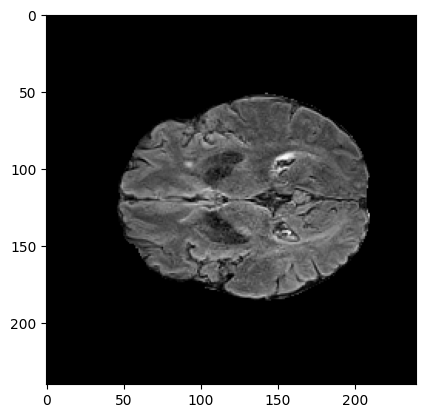

(150, 200)


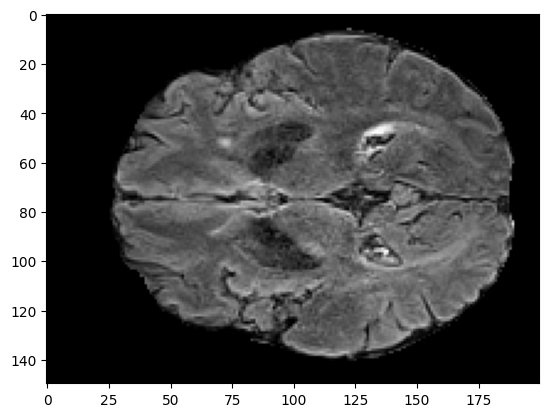

In [12]:
print(val_flair.shape)
plt.imshow(val_flair, cmap='gray')
plt.show()

center_x, center_y = val_flair.shape[0] // 2 , val_flair.shape[1] // 2
width_x = 75
width_y = 100

x = val_flair[center_x-width_x:center_x+width_x, center_y-width_y:center_y+width_y]
print(x.shape)
plt.imshow(x, cmap='gray')
plt.show()



Processing: 376files [00:04, 77.26files/s]


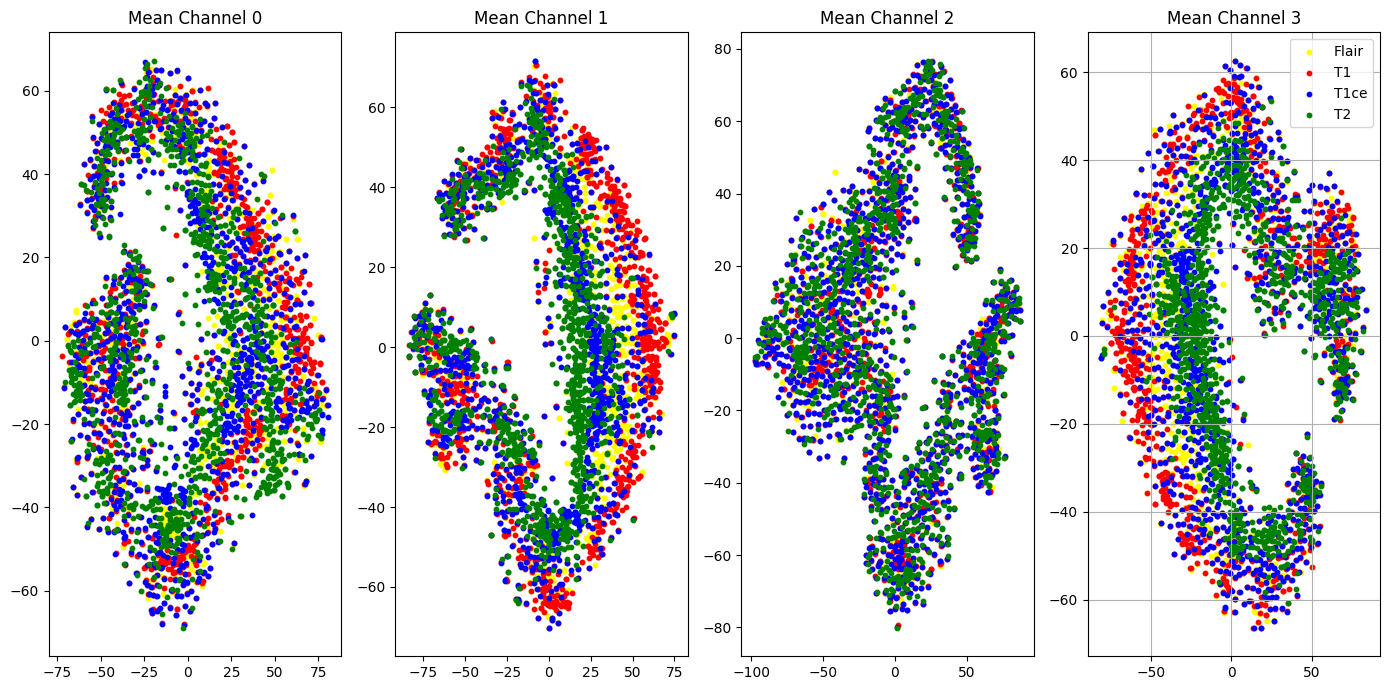

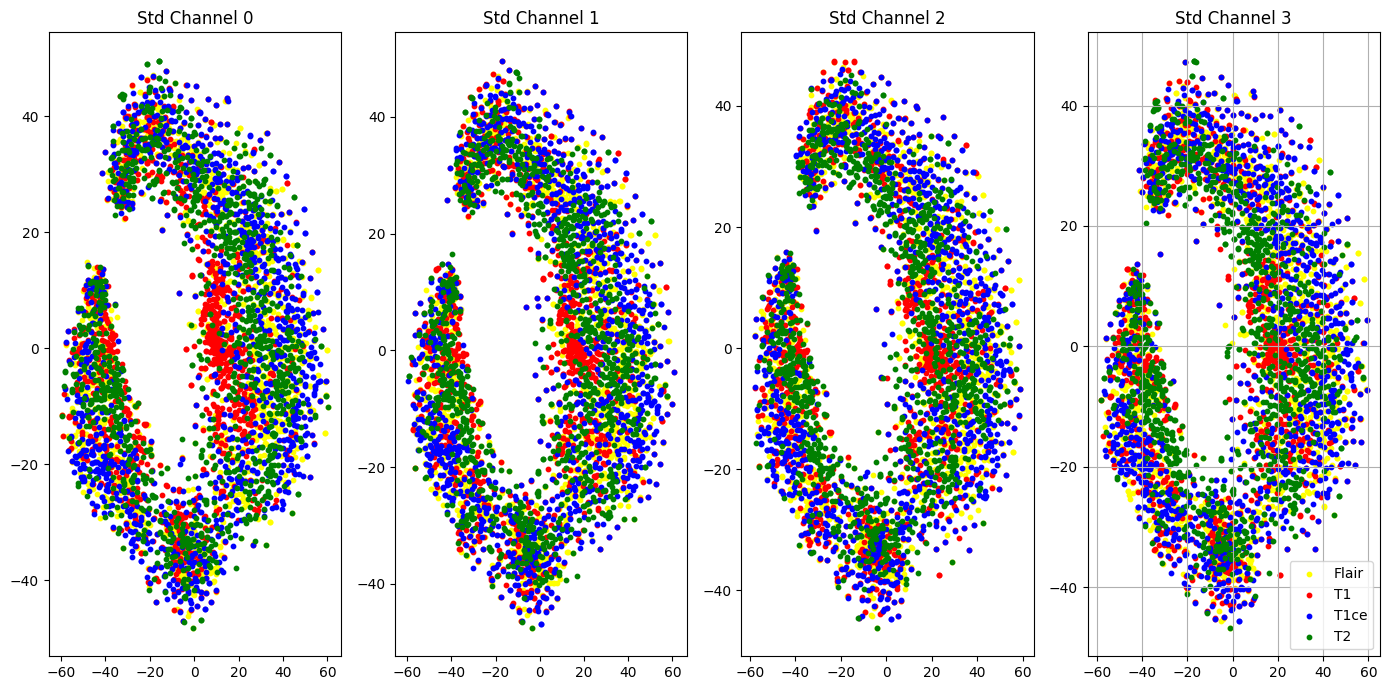

In [6]:
#"""

import numpy as np
from tqdm import tqdm
import os
import random
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

#x = np.random.rand(4,32,32)
#x = x.mean(axis=(1,2))
#print(x.shape)

val_root = '/home/sysgen/Desktop/Priyank/Datasets/brats24/BraTS-GLI/numpy_files_val/'

colors = {'T1': 'red', 'T1ce': 'blue', 'T2': 'green', 'Flair': 'yellow'}

means = []
means_0 = []
means_1 = []
means_2 = []
means_3 = []

stds = []
stds_0 = []
stds_1 = []
stds_2 = []
stds_3 = []


mods = []
cols = []

with tqdm(desc="Processing", unit="files") as pbar:
    for subject_dir, _, files in os.walk(val_root):
        files = [f for f in files if f.endswith(".npz")]
        
        random.shuffle(files)
        files = files[:3]
        
        for file in files:
            
            data = np.load(os.path.join(val_root, subject_dir, file))
            
            #means = [data['t1_latent_mean'], data['t1ce_latent_mean'], data['t2_latent_mean'], data['flair_latent_mean']]
            #stds = [data['t1_latent_std'], data['t1ce_latent_std'], data['t2_latent_std'], data['flair_latent_std']]
            
            # All 4 channels
            #means.append(data['t1_latent_mean'].flatten())
            #means.append(data['t1ce_latent_mean'].flatten())
            #means.append(data['t2_latent_mean'].flatten())
            #means.append(data['flair_latent_mean'].flatten())
            
            # Compare 1st mean channel only
            means.append(data['t1_latent_mean'].flatten())
            means.append(data['t1ce_latent_mean'].flatten())
            means.append(data['t2_latent_mean'].flatten())
            means.append(data['flair_latent_mean'].flatten())
            
            means_0.append(data['t1_latent_mean'][0].flatten())
            means_0.append(data['t1ce_latent_mean'][0].flatten())
            means_0.append(data['t2_latent_mean'][0].flatten())
            means_0.append(data['flair_latent_mean'][0].flatten())
            
            means_1.append(data['t1_latent_mean'][1].flatten())
            means_1.append(data['t1ce_latent_mean'][1].flatten())
            means_1.append(data['t2_latent_mean'][1].flatten())
            means_1.append(data['flair_latent_mean'][1].flatten())
            
            means_2.append(data['t1_latent_mean'][2].flatten())
            means_2.append(data['t1ce_latent_mean'][2].flatten())
            means_2.append(data['t2_latent_mean'][2].flatten())
            means_2.append(data['flair_latent_mean'][2].flatten())
            
            means_3.append(data['t1_latent_mean'][3].flatten())
            means_3.append(data['t1ce_latent_mean'][3].flatten())
            means_3.append(data['t2_latent_mean'][3].flatten())
            means_3.append(data['flair_latent_mean'][3].flatten())
            
            
            # Compare std channel
            stds.append(data['t1_latent_std'].flatten())
            stds.append(data['t1ce_latent_std'].flatten())
            stds.append(data['t2_latent_std'].flatten())
            stds.append(data['flair_latent_std'].flatten())
            
            stds_0.append(data['t1_latent_std'][0].flatten())
            stds_0.append(data['t1ce_latent_std'][0].flatten())
            stds_0.append(data['t2_latent_std'][0].flatten())
            stds_0.append(data['flair_latent_std'][0].flatten())
            
            stds_1.append(data['t1_latent_std'][1].flatten())
            stds_1.append(data['t1ce_latent_std'][1].flatten())
            stds_1.append(data['t2_latent_std'][1].flatten())
            stds_1.append(data['flair_latent_std'][1].flatten())
            
            stds_2.append(data['t1_latent_std'][2].flatten())
            stds_2.append(data['t1ce_latent_std'][2].flatten())
            stds_2.append(data['t2_latent_std'][2].flatten())
            stds_2.append(data['flair_latent_std'][2].flatten())
            
            stds_3.append(data['t1_latent_std'][3].flatten())
            stds_3.append(data['t1ce_latent_std'][3].flatten())
            stds_3.append(data['t2_latent_std'][3].flatten())
            stds_3.append(data['flair_latent_std'][3].flatten())
            
            
            mods.append('T1')
            mods.append('T1ce')
            mods.append('T2')
            mods.append('Flair')
            cols.append(colors['T1'])
            cols.append(colors['T1ce'])
            cols.append(colors['T2'])
            cols.append(colors['Flair'])
            
        pbar.update(1)  # Update progress bar for each subject processed

mods = np.array(mods)


# Convert to NumPy
means = np.array(means)
means_0 = np.array(means_0)
means_1 = np.array(means_1)
means_2 = np.array(means_2)
means_3 = np.array(means_3)


# Run t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30, init='pca')
#tsne_result = tsne.fit_transform(means)
tsne_result_0 = tsne.fit_transform(means_0)
tsne_result_1 = tsne.fit_transform(means_1)
tsne_result_2 = tsne.fit_transform(means_2)
tsne_result_3 = tsne.fit_transform(means_3)

# Plot
#plt.figure(figsize=(6, 6))
fig, ax = plt.subplots(1, 4, figsize=(14, 7))
colors = {'T1': 'red', 'T1ce': 'blue', 'T2': 'green', 'Flair': 'yellow'}

for mod in np.unique(mods):
    idx = np.where(mods == mod)[0]
    #ax[0].scatter(tsne_result[idx, 0], tsne_result[idx, 1], label=mod, c=colors[mod], s=10)
    ax[0].scatter(tsne_result_0[idx, 0], tsne_result_0[idx, 1], label=mod, c=colors[mod], s=10)
    ax[1].scatter(tsne_result_1[idx, 0], tsne_result_1[idx, 1], label=mod, c=colors[mod], s=10)
    ax[2].scatter(tsne_result_2[idx, 0], tsne_result_2[idx, 1], label=mod, c=colors[mod], s=10)
    ax[3].scatter(tsne_result_3[idx, 0], tsne_result_3[idx, 1], label=mod, c=colors[mod], s=10)
    #plt.scatter(tsne_result[idx, 0], tsne_result[idx, 1], label=mod, c=colors[mod], s=10)

ax[0].set_title("Mean Channel 0")
ax[1].set_title("Mean Channel 1")
ax[2].set_title("Mean Channel 2")
ax[3].set_title("Mean Channel 3")

plt.legend()
#plt.title("t-SNE of Latent Means by Modality")
plt.grid(True)
plt.tight_layout()
plt.show()









#STDS

stds = np.array(stds)
stds_0 = np.array(stds_0)
stds_1 = np.array(stds_1)
stds_2 = np.array(stds_2)
stds_3 = np.array(stds_3)

# Run t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30, init='pca')
#tsne_result = tsne.fit_transform(means)
tsne_result_0 = tsne.fit_transform(stds_0)
tsne_result_1 = tsne.fit_transform(stds_1)
tsne_result_2 = tsne.fit_transform(stds_2)
tsne_result_3 = tsne.fit_transform(stds_3)

# Plot
#plt.figure(figsize=(6, 6))
fig, ax = plt.subplots(1, 4, figsize=(14, 7))
colors = {'T1': 'red', 'T1ce': 'blue', 'T2': 'green', 'Flair': 'yellow'}

for mod in np.unique(mods):
    idx = np.where(mods == mod)[0]
    #ax[0].scatter(tsne_result[idx, 0], tsne_result[idx, 1], label=mod, c=colors[mod], s=10)
    ax[0].scatter(tsne_result_0[idx, 0], tsne_result_0[idx, 1], label=mod, c=colors[mod], s=10)
    ax[1].scatter(tsne_result_1[idx, 0], tsne_result_1[idx, 1], label=mod, c=colors[mod], s=10)
    ax[2].scatter(tsne_result_2[idx, 0], tsne_result_2[idx, 1], label=mod, c=colors[mod], s=10)
    ax[3].scatter(tsne_result_3[idx, 0], tsne_result_3[idx, 1], label=mod, c=colors[mod], s=10)
    #plt.scatter(tsne_result[idx, 0], tsne_result[idx, 1], label=mod, c=colors[mod], s=10)

ax[0].set_title("Std Channel 0")
ax[1].set_title("Std Channel 1")
ax[2].set_title("Std Channel 2")
ax[3].set_title("Std Channel 3")

plt.legend()
#plt.title("t-SNE of Latent Means by Modality")
plt.grid(True)
plt.tight_layout()
plt.show()



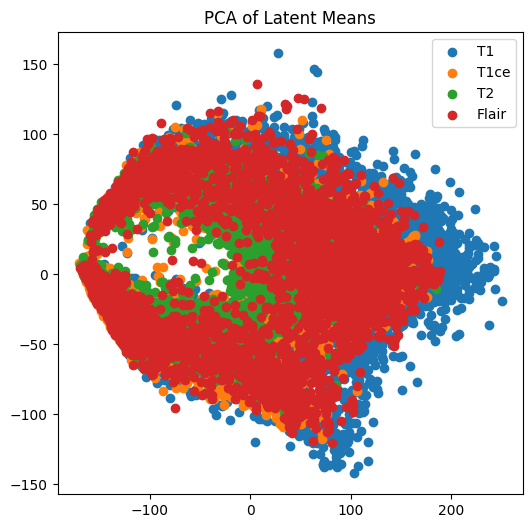

In [ ]:
"""
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
pca_result = pca.fit_transform(means)

# Visualize
plt.figure(figsize=(6, 6))
for mod in ['T1', 'T1ce', 'T2', 'Flair']:
    idx = [i for i, m in enumerate(mods) if m == mod]
    plt.scatter(pca_result[idx, 0], pca_result[idx, 1], label=mod)
plt.legend()
plt.title("PCA of Latent Means")
plt.show()
"""